# Análise da carteira de beneficiários · Vértice Saúde

> ⚠️ **Dados fictícios.** A operadora, as empresas e os beneficiários foram gerados para demonstração, mantendo a estrutura e os padrões de uma base real.

**Contexto.** A operadora acompanha sua carteira de vidas por relatórios extraídos do sistema. Este notebook faz a análise que um time de estratégia faria antes de construir um painel: confere a qualidade dos dados, define os indicadores e responde às perguntas de negócio.

**Perguntas de negócio**

1. A base é confiável? O que precisa ser tratado antes de calcular indicadores?
2. Qual o retrato atual da carteira (tamanho, perfil etário pelas faixas da ANS, regiões)?
3. A carteira está crescendo de forma saudável? Qual o churn mensal?
4. Quanto tempo os beneficiários ficam? Qual safra retém melhor?
5. O que explica a alta de cancelamentos de jul–ago/2026?
6. A carteira PJ depende de poucas empresas?

**Data de referência:** 31/08/2026 (data de extração da base). Os mesmos indicadores estão em SQL na pasta `analises/sql`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.1f}".replace(",", "X").replace(".", ",").replace("X", "."))

DATA_REF = pd.Timestamp("2026-08-31")

# Paleta categórica validada para daltonismo (ordem fixa) e estilo enxuto
AZUL, LARANJA, VERDE_AGUA, AMARELO, CINZA = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a8984"
plt.rcParams.update({
    "figure.figsize": (10, 4.2), "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.edgecolor": "#bdbcb7", "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.titlelocation": "left", "font.size": 10, "legend.frameon": False,
})
MESES = ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"]
rotulo_mes = lambda p: f"{MESES[p.month - 1]}/{str(p.year)[2:]}"
fmt_mil = mtick.FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", "."))

## 1. Carga dos dados

In [2]:
colunas = {
    "Código do usuário": "codigo", "Data de Inclusão": "data_inclusao", "Empresa": "empresa",
    "Idade": "idade", "Sexo": "sexo", "Situação": "situacao", "Data de cancelamento": "data_cancelamento",
    "Motivo do cancelamento": "motivo_original", "Cidade de correspondência": "cidade",
    "Estado de correspondência": "uf", "Descrição do plano": "plano",
}
bruto = pd.read_csv("../../public/beneficiarios-publico.csv", sep=";", encoding="utf-8-sig",
                    dtype=str, keep_default_na=False).rename(columns=colunas)
mapa_motivos = pd.read_csv("../dados/mapa_motivos.csv", sep=";", dtype=str)

print(f"{len(bruto):,} registros · {bruto.shape[1]} colunas".replace(",", "."))
bruto.head()

190.652 registros · 11 colunas


,codigo,data_inclusao,empresa,idade,sexo,situacao,data_cancelamento,motivo_original,cidade,uf,plano
0,F5882353,15/07/2025,,5,FEMININO,CANCELADO,30/05/2026,INADIMPLENCIA,GOIANIA,GO,VERTICE SUPERIOR INDIVIDUAL 100 - ENFERMARIA
1,F4037928,13/08/2026,NORTE LIMPEZA S.A.,11,MASCULINO,ATIVO,,,MACAPA,AP,VERTICE MASTER ADESAO 120 - ENFERMARIA
2,F6649972,08/12/2025,NOVA ERA DISTRIBUIDORA EPP,37,FEMININO,CANCELADO,18/05/2026,CANCELAMENTO INSATIS,BOA VISTA DO TUPIM,BA,VERTICE PLENO EMPRESARIAL 100 - ENFERMARIA
3,F4064868,04/05/2026,,74,FEMININO,ATIVO,,,JABOATAO DOS GUARARAPES,PE,VERTICE MASTER INDIVIDUAL 120 - ENFERMARIA
4,F4417625,06/05/2026,SAFIRA UNIAO FARMA ME,68,FEMININO,CANCELADO,03/07/2026,CANCELAMENTO INDISPO,SALVADOR,BA,VERTICE MASTER EMPRESARIAL 120 - ENFERMARIA


## 2. Tratamento

- Datas e idade para os tipos certos; textos como "SEM CIDADE REGISTRADA" viram vazio.
- **Faixas etárias da ANS** (10 faixas usadas em preço e reajuste), no lugar de faixas genéricas.
- **Segmento e acomodação** extraídos do nome do plano.
- **Motivos de cancelamento padronizados.** O sistema corta o texto em 20 caracteres e grava o mesmo motivo de formas diferentes ("FALECIDO", "CANCELAMENTO FALECIM"…). Um de-para agrupa em categorias de negócio.

In [3]:
df = bruto.copy()
df["data_inclusao"] = pd.to_datetime(df["data_inclusao"], format="%d/%m/%Y")
df["data_cancelamento"] = pd.to_datetime(df["data_cancelamento"].replace("", None), format="%d/%m/%Y")
df["idade"] = pd.to_numeric(df["idade"], errors="coerce")
df["empresa"] = df["empresa"].str.strip().replace("", None)
df["cidade"] = df["cidade"].replace("SEM CIDADE REGISTRADA", None)
df["uf"] = df["uf"].replace("SEM ESTADO REGISTRADO", None)
df["motivo_original"] = df["motivo_original"].str.strip().replace("", None)

df["tipo_cadastro"] = np.where(df["empresa"].isna() | (df["empresa"] == "PF"), "PF", "PJ")

FAIXAS_ANS = ["00 a 18", "19 a 23", "24 a 28", "29 a 33", "34 a 38",
              "39 a 43", "44 a 48", "49 a 53", "54 a 58", "59 ou mais"]
df["faixa_ans"] = pd.cut(df["idade"], bins=[-1, 18, 23, 28, 33, 38, 43, 48, 53, 58, 200],
                         labels=FAIXAS_ANS)

df["segmento"] = df["plano"].str.extract(r"^VERTICE \S+ (\S+)")[0].fillna("OUTROS")
df["acomodacao"] = np.where(df["plano"].str.contains("APARTAMENTO"), "Apartamento", "Enfermaria")

df = df.merge(mapa_motivos, on="motivo_original", how="left")
sem_motivo = df["motivo_original"].isna()
df["motivo_grupo"] = df["motivo_grupo"].fillna(pd.Series(np.where(sem_motivo, "Sem motivo", "Não mapeado"), index=df.index))

print("Motivos originais:", df["motivo_original"].nunique(),
      "→ descrições padronizadas:", df["motivo_descricao"].nunique(),
      "→ grupos:", df.loc[~sem_motivo, "motivo_grupo"].nunique())
print("Motivos sem de-para:", (df["motivo_grupo"] == "Não mapeado").sum())

Motivos originais: 34 → descrições padronizadas: 29 → grupos: 12
Motivos sem de-para: 0


## 3. Qualidade dos dados

Antes de qualquer indicador: quanto da base **não representa um cliente real na carteira**?

In [4]:
df["em_digitacao"] = df["situacao"].eq("DIGITAÇÃO")
df["datas_inconsistentes"] = df["data_cancelamento"] < df["data_inclusao"]
df["erro_cadastral"] = df["motivo_grupo"].eq("Erro cadastral")
df["base_valida"] = ~(df["em_digitacao"] | df["datas_inconsistentes"] | df["erro_cadastral"])

# Migração = troca de contrato (saída técnica). Perda = cancelamento real.
df["migracao"] = df["situacao"].eq("MIGRADO") | df["motivo_grupo"].eq("Migração")
df["perda"] = df["base_valida"] & df["data_cancelamento"].notna() & ~df["migracao"]

total = len(df)
qualidade = pd.DataFrame({
    "registros": {
        "Sem cidade/UF registrada": df["uf"].isna().sum(),
        "Em digitação (ainda não ativos)": df["em_digitacao"].sum(),
        "Erro cadastral (gerado indevidamente/duplicado)": df["erro_cadastral"].sum(),
        "Cancelado sem motivo informado": (df["situacao"].eq("CANCELADO") & sem_motivo).sum(),
        "Cancelamento antes da inclusão": df["datas_inconsistentes"].sum(),
        "Fora da base válida (excluídos das análises)": (~df["base_valida"]).sum(),
    }
})
qualidade["% da base"] = 100 * qualidade["registros"] / total
qualidade

,registros,% da base
Sem cidade/UF registrada,15412,"8,1"
Em digitação (ainda não ativos),4372,"2,3"
Erro cadastral (gerado indevidamente/duplicado),14320,"7,5"
Cancelado sem motivo informado,3682,"1,9"
Cancelamento antes da inclusão,63,"0,0"
Fora da base válida (excluídos das análises),18750,"9,8"


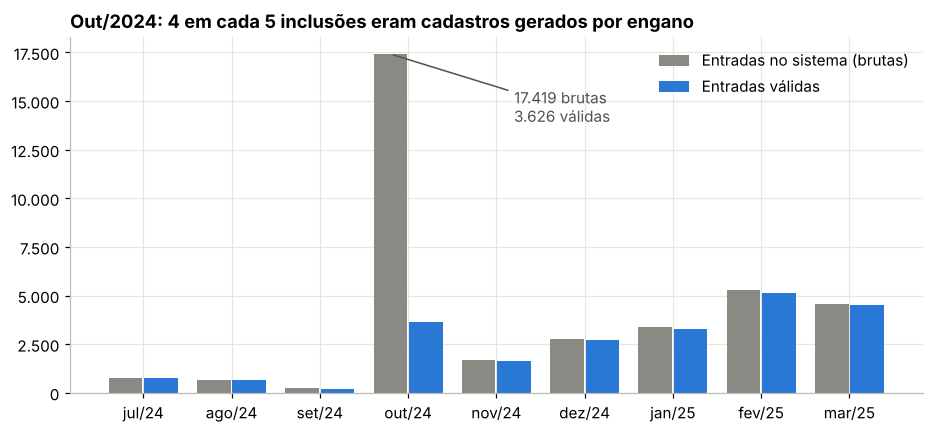

In [5]:
janela = df[(df["data_inclusao"] >= "2024-07-01") & (df["data_inclusao"] < "2025-04-01")]
entradas = (janela.groupby(janela["data_inclusao"].dt.to_period("M"))
            .agg(brutas=("codigo", "size"), validas=("base_valida", "sum")))

fig, ax = plt.subplots()
x = np.arange(len(entradas))
ax.bar(x - 0.2, entradas["brutas"], width=0.38, color=CINZA, label="Entradas no sistema (brutas)")
ax.bar(x + 0.2, entradas["validas"], width=0.38, color=AZUL, label="Entradas válidas")
ax.set_xticks(x, [rotulo_mes(p) for p in entradas.index])
ax.yaxis.set_major_formatter(fmt_mil)
ax.set_title("Out/2024: 4 em cada 5 inclusões eram cadastros gerados por engano")
ax.legend(loc="upper right")
out24 = entradas.loc["2024-10"]
ax.annotate(f"{out24['brutas']:,.0f} brutas\n{out24['validas']:,.0f} válidas".replace(",", "."),
            xy=(3 - 0.2, out24["brutas"]), xytext=(4.2, out24["brutas"] * 0.8),
            arrowprops=dict(arrowstyle="-", color="#52514e"), color="#52514e")
plt.show()

**Leitura.** Em outubro de 2024 o sistema registrou um lote de cadastros "gerados indevidamente", cancelados poucos dias depois. Sem tratamento, um painel mostraria um salto de crescimento seguido de uma onda de cancelamentos, e **os dois seriam falsos**. Por isso todas as análises a seguir usam a **base válida**.

In [6]:
base = df[df["base_valida"]].copy()
print(f"Base válida: {len(base):,} registros ({100*len(base)/total:.1f}% do total)".replace(",", "."))

Base válida: 171.902 registros (90.2% do total)


## 4. Retrato da carteira na data de referência

In [7]:
ativos = df[df["situacao"].eq("ATIVO") & (df["data_inclusao"] <= DATA_REF)]

def ativos_em(data):
    """Vidas da base válida ativas em uma data (reconstrói o estoque histórico)."""
    return ((base["data_inclusao"] <= data) &
            (base["data_cancelamento"].isna() | (base["data_cancelamento"] > data))).sum()

ha_12m = DATA_REF - pd.DateOffset(months=12)
kpis = pd.Series({
    "Vidas ativas": len(ativos),
    "Pessoa Física": (ativos["tipo_cadastro"] == "PF").sum(),
    "Pessoa Jurídica": (ativos["tipo_cadastro"] == "PJ").sum(),
    "Idade média": ativos["idade"].mean(),
    "% com 59 anos ou mais": 100 * (ativos["faixa_ans"] == "59 ou mais").mean(),
    "Crescimento em 12 meses (%)": 100 * (len(ativos) / ativos_em(ha_12m) - 1),
    "Perdas nos últimos 12 meses": (base["perda"] & (base["data_cancelamento"] > ha_12m)).sum(),
}, name="valor")
kpis.to_frame()

,valor
Vidas ativas,"87.081,0"
Pessoa Física,"22.699,0"
Pessoa Jurídica,"64.382,0"
Idade média,"32,5"
% com 59 anos ou mais,"9,4"
Crescimento em 12 meses (%),"81,7"
Perdas nos últimos 12 meses,"45.846,0"


0 a 18 anos: 25.7% · 59 anos ou mais: 9.4% da carteira


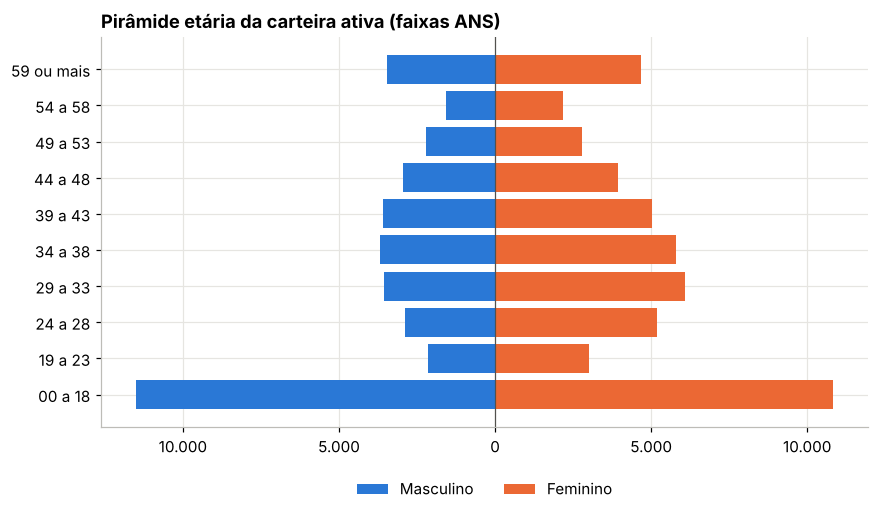

In [8]:
piramide = ativos.groupby(["faixa_ans", "sexo"], observed=False).size().unstack(fill_value=0)

fig, ax = plt.subplots(figsize=(9, 4.6))
y = np.arange(len(piramide))
ax.barh(y, -piramide["MASCULINO"], color=AZUL, height=0.8, label="Masculino")
ax.barh(y, piramide["FEMININO"], color=LARANJA, height=0.8, label="Feminino")
ax.set_yticks(y, piramide.index)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{abs(v):,.0f}".replace(",", ".")))
ax.axvline(0, color="#52514e", linewidth=0.8)
ax.set_title("Pirâmide etária da carteira ativa (faixas ANS)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2)
plt.show()

pct = 100 * piramide.sum(axis=1) / piramide.values.sum()
print(f"0 a 18 anos: {pct['00 a 18']:.1f}% · 59 anos ou mais: {pct['59 ou mais']:.1f}% da carteira")

In [9]:
por_uf = ativos["uf"].fillna("Sem UF").value_counts()
tabela_uf = pd.DataFrame({"vidas": por_uf, "%": 100 * por_uf / por_uf.sum()})
tabela_uf["% acumulado"] = tabela_uf["%"].cumsum()
tabela_uf.head(8)

,vidas,%,% acumulado
uf,,,
BA,15961,"18,3","18,3"
MA,15158,"17,4","35,7"
PE,14933,"17,1","52,9"
SC,10574,"12,1","65,0"
SE,6362,"7,3","72,3"
RO,4628,"5,3","77,6"
AM,4265,"4,9","82,5"
PR,3734,"4,3","86,8"


## 5. Movimentação e churn mensal

**Churn mensal** = perdas do mês ÷ vidas ativas no 1º dia do mês. Migrações (troca de contrato) não contam como perda.

In [10]:
meses = pd.period_range("2024-01", DATA_REF.to_period("M"), freq="M")
linhas = []
for m in meses:
    ini, fim = m.start_time, m.end_time
    linhas.append({
        "mes": m,
        "ativos_inicio": ((base["data_inclusao"] < ini) &
                          (base["data_cancelamento"].isna() | (base["data_cancelamento"] >= ini))).sum(),
        "entradas": base["data_inclusao"].between(ini, fim).sum(),
        "perdas": (base["perda"] & base["data_cancelamento"].between(ini, fim)).sum(),
        "migracoes": (base["migracao"] & base["data_cancelamento"].between(ini, fim)).sum(),
    })
mov = pd.DataFrame(linhas).set_index("mes")
mov["saldo"] = mov["entradas"] - mov["perdas"] - mov["migracoes"]
mov["churn_%"] = 100 * mov["perdas"] / mov["ativos_inicio"]
mov.tail(8)

,ativos_inicio,entradas,perdas,migracoes,saldo,churn_%
mes,,,,,,
2026-01,73438,4937,1987,93,2857,"2,7"
2026-02,76295,5609,1749,29,3831,"2,3"
2026-03,80126,7132,1919,47,5166,"2,4"
2026-04,85292,9452,1978,68,7406,"2,3"
2026-05,92698,10455,2708,46,7701,"2,9"
2026-06,100399,9978,4901,54,5023,"4,9"
2026-07,105422,4222,8145,72,-3995,"7,7"
2026-08,101427,2013,16332,27,-14346,"16,1"


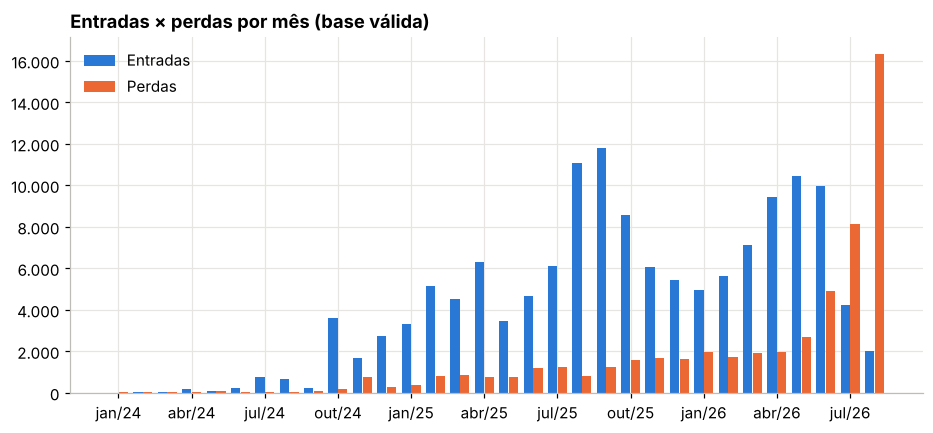

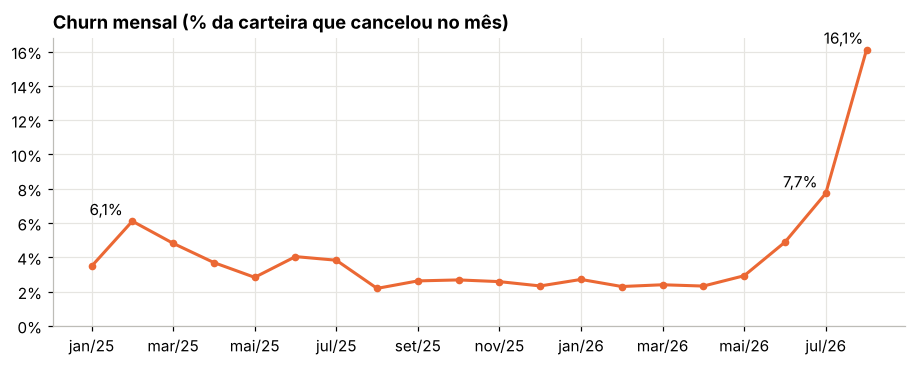

In [11]:
rotulos = [rotulo_mes(p) for p in mov.index]
x = np.arange(len(mov))

fig, ax = plt.subplots()
ax.bar(x - 0.2, mov["entradas"], width=0.38, color=AZUL, label="Entradas")
ax.bar(x + 0.2, mov["perdas"], width=0.38, color=LARANJA, label="Perdas")
ax.set_xticks(x[::3], rotulos[::3])
ax.yaxis.set_major_formatter(fmt_mil)
ax.set_title("Entradas × perdas por mês (base válida)")
ax.legend(loc="upper left")
plt.show()

recorte = mov.loc["2025-01":]
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(np.arange(len(recorte)), recorte["churn_%"], color=LARANJA, linewidth=2, marker="o", markersize=4)
ax.set_xticks(np.arange(len(recorte))[::2], [rotulo_mes(p) for p in recorte.index][::2])
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_ylim(0)
ax.set_title("Churn mensal (% da carteira que cancelou no mês)")
for i, (p, v) in enumerate(recorte["churn_%"].items()):
    if v > 6:
        ax.annotate(f"{v:.1f}%".replace(".", ","), (i, v), xytext=(-28, 4), textcoords="offset points")
plt.show()

### Alerta automático de churn

Um mês é sinalizado quando o churn passa de **2x a mediana dos 12 meses anteriores**. Usar a taxa, e não a quantidade de perdas, evita confundir crescimento da carteira com anomalia.

In [12]:
mov["churn_mediano_12m"] = mov["churn_%"].shift(1).rolling(12, min_periods=6).median()
alertas = mov[mov["churn_%"] > 2 * mov["churn_mediano_12m"]].copy()
alertas["perdas_excedentes"] = (alertas["perdas"] -
                                alertas["ativos_inicio"] * alertas["churn_mediano_12m"] / 100).round()
alertas[["ativos_inicio", "perdas", "churn_%", "churn_mediano_12m", "perdas_excedentes"]]

,ativos_inicio,perdas,churn_%,churn_mediano_12m,perdas_excedentes
mes,,,,,
2024-10,3674,172,"4,7","1,9","100,0"
2024-11,7040,746,"10,6","2,0","605,0"
2025-02,13300,812,"6,1","2,1","528,0"
2026-07,105422,8145,"7,7","2,6","5.405,0"
2026-08,101427,16332,"16,1","2,6","13.696,0"


## 6. Retenção por safra (coortes)

De cada mês de entrada, qual % das vidas continuava na carteira depois de N meses? Migrados ficam fora do cálculo.

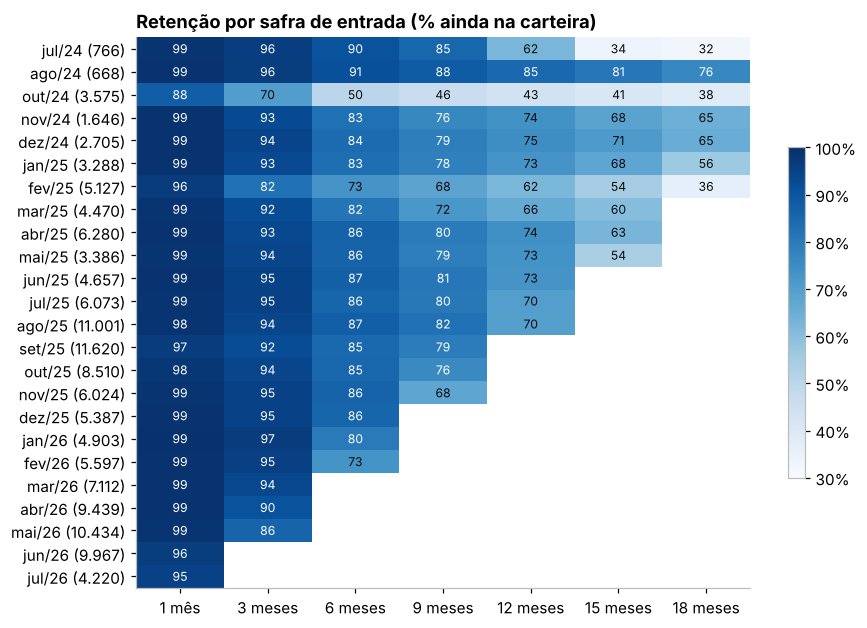

In [13]:
safras = base[~base["migracao"] & (base["data_inclusao"] >= "2024-07-01")].copy()
safras["safra"] = safras["data_inclusao"].dt.to_period("M")
PRAZOS = [1, 3, 6, 9, 12, 15, 18]

matriz = {}
for k in PRAZOS:
    marco = safras["data_inclusao"] + pd.DateOffset(months=k)
    elegivel = marco <= DATA_REF
    retido = safras["data_cancelamento"].isna() | (safras["data_cancelamento"] >= marco)
    g = pd.DataFrame({"safra": safras["safra"], "e": elegivel, "r": retido & elegivel}).groupby("safra")
    matriz[f"{k}m"] = 100 * g["r"].sum() / g["e"].sum().replace(0, np.nan)
matriz = pd.DataFrame(matriz)
matriz.insert(0, "vidas", safras.groupby("safra").size())
matriz = matriz[matriz["vidas"] >= 500].dropna(subset=["1m"])

fig, ax = plt.subplots(figsize=(9, 6.5))
valores = matriz[[f"{k}m" for k in PRAZOS]]
im = ax.imshow(valores, cmap="Blues", vmin=30, vmax=100, aspect="auto")
ax.set_xticks(range(len(PRAZOS)), ["1 mês" if k == 1 else f"{k} meses" for k in PRAZOS])
ax.set_yticks(range(len(valores)), [f"{rotulo_mes(p)} ({n:,.0f})".replace(",", ".") for p, n in zip(valores.index, matriz["vidas"])])
ax.grid(False)
for i in range(valores.shape[0]):
    for j in range(valores.shape[1]):
        v = valores.iat[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8,
                    color="white" if v > 75 else "#0b0b0b")
ax.set_title("Retenção por safra de entrada (% ainda na carteira)")
fig.colorbar(im, ax=ax, shrink=0.6, format=mtick.PercentFormatter(decimals=0))
plt.show()

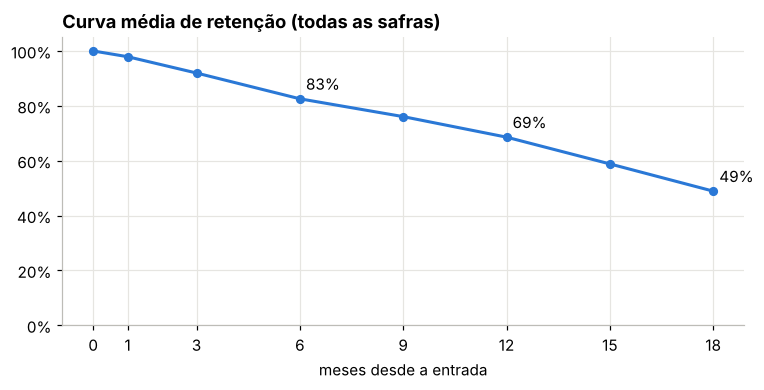

In [14]:
curva = {}
for k in PRAZOS:
    marco = safras["data_inclusao"] + pd.DateOffset(months=k)
    elegivel = marco <= DATA_REF
    retido = safras["data_cancelamento"].isna() | (safras["data_cancelamento"] >= marco)
    curva[k] = 100 * (retido & elegivel).sum() / elegivel.sum()
curva = pd.Series(curva, name="retenção %")

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot([0] + list(curva.index), [100] + list(curva.values), color=AZUL, linewidth=2, marker="o", markersize=5)
for k, v in curva.items():
    if k in (6, 12, 18):
        ax.annotate(f"{v:.0f}%", (k, v), xytext=(4, 6), textcoords="offset points")
ax.set_ylim(0, 105)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_xticks([0] + PRAZOS)
ax.set_xlabel("meses desde a entrada")
ax.set_title("Curva média de retenção (todas as safras)")
plt.show()

## 7. Tempo de permanência até o cancelamento

In [15]:
perdas = base[base["perda"]].copy()
perdas["meses"] = (perdas["data_cancelamento"] - perdas["data_inclusao"]).dt.days / 30.4375

resumo_motivo = (perdas.groupby("motivo_grupo")
                 .agg(perdas=("meses", "size"), mediana_meses=("meses", "median"),
                      sai_antes_3m=("meses", lambda s: 100 * (s < 3).mean()))
                 .sort_values("perdas", ascending=False))
resumo_motivo["% das perdas"] = 100 * resumo_motivo["perdas"] / resumo_motivo["perdas"].sum()
resumo_motivo

,perdas,mediana_meses,sai_antes_3m,% das perdas
motivo_grupo,,,,
Rescisão do contrato,36113,"10,5","18,7","44,4"
Financeiro,23197,"6,0","16,9","28,5"
Insatisfação,15257,"8,0","14,4","18,7"
Sem motivo,3674,"9,0","17,4","4,5"
Não utilização,1509,"4,1","39,4","1,9"
Outros,673,"8,6","41,2","0,8"
Falecimento,260,"12,6","17,3","0,3"
Desistência,254,"0,1","99,6","0,3"
Portabilidade,251,"32,4","3,6","0,3"


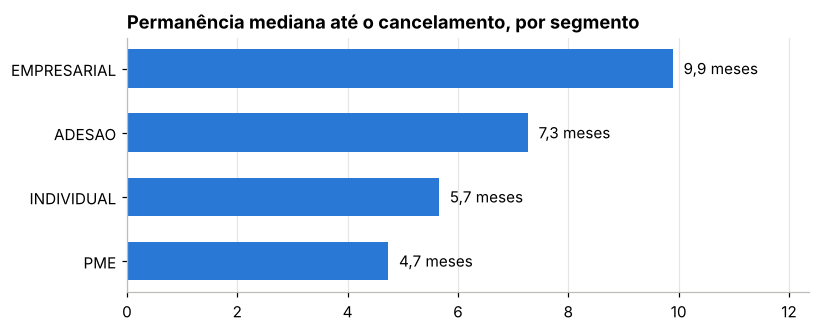

In [16]:
resumo_segmento = (perdas.groupby("segmento")["meses"]
                   .agg(perdas="size", media="mean", mediana="median")
                   .sort_values("mediana"))

fig, ax = plt.subplots(figsize=(8, 3))
ax.barh(resumo_segmento.index, resumo_segmento["mediana"], color=AZUL, height=0.6)
for i, v in enumerate(resumo_segmento["mediana"]):
    ax.text(v + 0.2, i, f"{v:.1f} meses".replace(".", ","), va="center")
ax.set_title("Permanência mediana até o cancelamento, por segmento")
ax.set_xlim(0, resumo_segmento["mediana"].max() * 1.25)
ax.grid(axis="y", visible=False)
plt.show()

## 8. O que explica a alta de cancelamentos de jul–ago/2026?

Comparação da média mensal de perdas por motivo: **jan–mai/2026** (período normal) × **jul–ago/2026** (alerta).

,jan–mai/26,jul–ago/26,variação (x)
motivo_grupo,,,
Insatisfação,"126,4","5.949,5","47,1"
Rescisão do contrato,"654,6","3.309,5","5,1"
Financeiro,"1.219,8","2.702,5","2,2"
Não utilização,"48,8","235,5","4,8"
Portabilidade,"2,6","12,5","4,8"


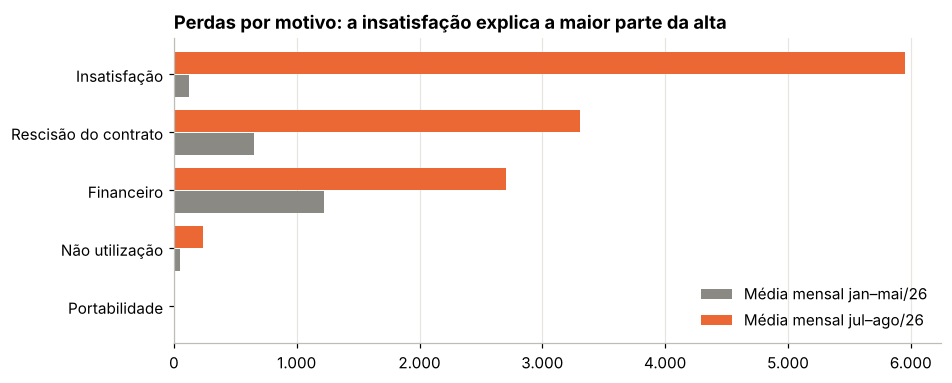

In [17]:
def media_mensal(inicio, fim, n_meses):
    recorte = perdas[perdas["data_cancelamento"].between(inicio, fim)]
    return recorte["motivo_grupo"].value_counts() / n_meses

comparacao = pd.DataFrame({
    "jan–mai/26": media_mensal("2026-01-01", "2026-05-31", 5),
    "jul–ago/26": media_mensal("2026-07-01", "2026-08-31", 2),
}).fillna(0)
comparacao["variação (x)"] = comparacao["jul–ago/26"] / comparacao["jan–mai/26"]
comparacao = comparacao.sort_values("jul–ago/26", ascending=False).head(5)

fig, ax = plt.subplots(figsize=(9, 3.6))
y = np.arange(len(comparacao))
ax.barh(y + 0.2, comparacao["jan–mai/26"], height=0.38, color=CINZA, label="Média mensal jan–mai/26")
ax.barh(y - 0.2, comparacao["jul–ago/26"], height=0.38, color=LARANJA, label="Média mensal jul–ago/26")
ax.set_yticks(y, comparacao.index)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(fmt_mil)
ax.grid(axis="y", visible=False)
ax.set_title("Perdas por motivo: a insatisfação explica a maior parte da alta")
ax.legend(loc="lower right")
plt.show()
comparacao

## 9. Concentração da carteira PJ

11.662 empresas ativas · top 5 = 35.8% · top 12 = 50.9% das vidas PJ · HHI = 333


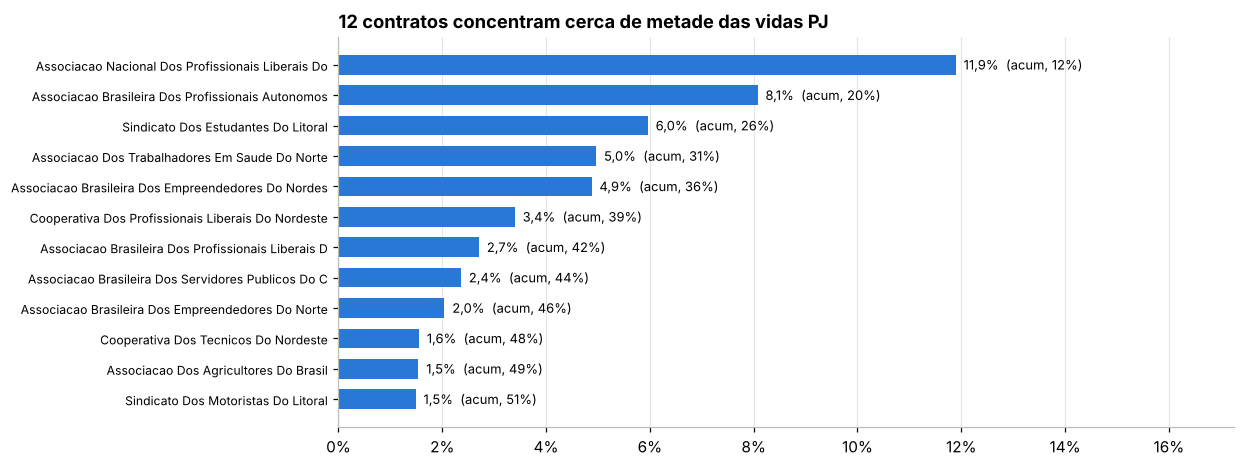

In [18]:
pj = ativos[ativos["tipo_cadastro"] == "PJ"]["empresa"].value_counts()
top = pd.DataFrame({"vidas": pj.head(12), "% da carteira PJ": 100 * pj.head(12) / pj.sum()})
top["% acumulado"] = top["% da carteira PJ"].cumsum()

hhi = ((100 * pj / pj.sum()) ** 2).sum()
print(f"{len(pj):,} empresas ativas · top 5 = {top['% da carteira PJ'].head(5).sum():.1f}% "
      f"· top 12 = {top['% acumulado'].iloc[-1]:.1f}% das vidas PJ · HHI = {hhi:,.0f}".replace(",", "."))

fig, ax = plt.subplots(figsize=(10.5, 4.6))
ax.barh(range(len(top)), top["% da carteira PJ"], color=AZUL, height=0.65)
ax.set_yticks(range(len(top)), [n.title() for n in top.index], fontsize=8)
ax.invert_yaxis()
for i, (v, acc) in enumerate(zip(top["% da carteira PJ"], top["% acumulado"])):
    ax.text(v + 0.15, i, f"{v:.1f}%  (acum. {acc:.0f}%)".replace(".", ","), va="center", fontsize=8.5)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_xlim(0, top["% da carteira PJ"].max() * 1.45)
ax.grid(axis="y", visible=False)
ax.set_title("12 contratos concentram cerca de metade das vidas PJ")
plt.show()

## 10. Conclusões e recomendações

**1. A base precisa de tratamento antes de virar indicador.** 9,8% dos registros não representam clientes reais (cadastros em digitação, erros cadastrais e datas inconsistentes). O caso mais grave foi out/2024: das 17.419 inclusões do mês, só 3.626 eram válidas. Sem esse filtro, o painel mostraria um crescimento falso seguido de uma onda de cancelamentos também falsa.
→ *Recomendação:* manter as regras de qualidade como etapa fixa do pipeline e monitorar o indicador de qualidade mês a mês.

**2. Carteira jovem, concentrada no Nordeste e majoritariamente PJ.** São 87.081 vidas ativas: 74% PJ, idade média de 32,5 anos e 25,7% na faixa de 0 a 18. Só 9,4% estão na faixa de 59 anos ou mais, o que é favorável para a sinistralidade. BA, MA e PE somam 53% da carteira.

**3. Crescimento forte, mas com um alerta recente.** A carteira cresceu 81,7% em 12 meses. O churn mensal ficou estável entre 2,3% e 2,9% de set/25 a mai/26 e então disparou: 4,9% em jun, 7,7% em jul e 16,1% em ago/26. O alerta automático estima cerca de 19 mil perdas acima do normal só em jul–ago.

**4. O motivo da alta é insatisfação.** As perdas por insatisfação foram de cerca de 126 por mês (jan–mai) para cerca de 5.950 por mês (jul–ago), 47 vezes mais. Rescisão de contratos também subiu 5 vezes.
→ *Recomendação:* investigar com as áreas de rede credenciada e atendimento o que mudou a partir de jun/26 (reajuste, descredenciamento, mudança de rede) e cruzar com dados de reclamações (NIP/ANS e SAC).

**5. Retenção: metade sai em até 18 meses.** Em média, 83% das vidas continuam após 6 meses, 69% após 12 e 49% após 18. PME e Individual têm a menor permanência (mediana de 4,7 e 5,7 meses até o cancelamento).
→ *Recomendação:* criar uma régua de relacionamento nos primeiros 6 meses, sobretudo para PME, Individual e para quem cancela por não utilização (39% saem antes de 3 meses).

**6. Risco de concentração na carteira PJ.** 5 contratos concentram 36% das vidas PJ e 12 contratos, 51%, quase todos associações (adesão). O índice HHI (333) parece baixo só porque há mais de 11 mil empresas pequenas: ele esconde o risco. A perda de um único contrato grande tira até 12% da carteira PJ.
→ *Recomendação:* acompanhar a saúde desses contratos em separado (renovação, reajuste, satisfação).

### Próximos passos
- Modelo de propensão a cancelamento (regressão logística ou árvore) usando o histórico de utilização e de reclamações, quando esses dados estiverem disponíveis.
- Incluir receita e sinistralidade para medir o impacto financeiro das perdas, e não só em número de vidas.